In [1]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Connect and Access Git Repository

import os
import sys
import json
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())

GitHub token: ··········
/content/bachelor-thesis
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 448 bytes | 224.00 KiB/s, done.
From https://github.com/sharaffatima/bachelor-thesis
   0518946..9cb0344  main       -> origin/main
Updating 0518946..9cb0344
error: Your local changes to the following files would be overwritten by merge:
	explainability/anoformer_attention.py
Please commit your changes or stash them before you merge.
Aborting
/content/bachelor-thesis
Repo exists: True


In [3]:
# Imports
import os
import numpy as np
import torch
from torch.utils.data import DataLoader

# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))


from utils.dataset import PTBXLDataset
from explainability.anoformer_attention import AnoFormerExplainability
from explainability.sample_selection import (
    save_test_outputs,
    load_test_outputs,
    check_same_labels,
    select_mutual_samples,
    save_output,
    load_output,
    load_samples_from_dataset
)
from utils.seed import set_seed, RANDOM_SEED
from models.anoformer import AnoFormerMainModel
from utils.anomaly_threshold import choose_threshold_for_recall
from explainability.visualization import plot_temporal_importance

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cuda


In [4]:
# Paths to Directories

DATA_DIR = Path("/content/drive/MyDrive/ECG data")
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"
EVALUATION_DIR = RESULTS_DIR / "evaluation"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

ANOFORMER_MODEL_DIR = MODEL_DIR / "anoformer"
ANOFORMER_MODEL_DIR.mkdir(parents=True, exist_ok=True)

ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs_larger_capacity_2.pt"

print("MODEL_DIR:", ANOFORMER_MODEL_DIR)
print("MODEL_PATH:", ANOFORMER_MODEL_PATH)

MODEL_DIR: /content/drive/MyDrive/ECG data/results/models/anoformer
MODEL_PATH: /content/drive/MyDrive/ECG data/results/models/anoformer/anoformer_40epochs_larger_capacity_2.pt


In [5]:
# Load my preprocessed data

X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(17418, 1000, 12) (17418,)
(2183, 1000, 12) (2183,)
(2198, 1000, 12) (2198,)


In [6]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

print("Training on normal ECGs:", X_train_normal.shape)

Training on normal ECGs: (7596, 1000, 12)


In [7]:
# Datasets

train_dataset = PTBXLDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [8]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [9]:
# Check the shapes

# Expected:
#         Batch X: torch.Size([4, 1000, 12])
#         Batch y: torch.Size([4])

batch_x, batch_y = next(iter(train_loader))

print(batch_x.shape)
print(batch_y.shape)

torch.Size([4, 1000, 12])
torch.Size([4])


In [10]:
# Create Model

AnoFormer = AnoFormerMainModel(
    NumFeatures=12,
    ModelDimension=64,
    NumHeads=4,
    NumEncoderLayers=2,
    NumDecoderLayers=2,
    DiscriminatorLayers=1,
    ForwardDimension=128,
    DropoutRate=0.1,
    GeneratorLearningRate=1e-4,
    DiscriminatorLearningRate=1e-4,
    MaskingRate=0.15,
    AnomalyThreshold=0.75,
    ReconstructionWeight=10.0,
)

In [11]:
# Test

batch_x, _ = next(iter(train_loader))
batch_x = batch_x.to(AnoFormer.Device)

with torch.no_grad():
    masked_x, _ = AnoFormer.Masking(batch_x, None)
    reconstruction = AnoFormer.Generator(masked_x)

print("Input:", batch_x.shape)
print("Masked:", masked_x.shape)
print("Reconstruction:", reconstruction.shape)

Input: torch.Size([4, 1000, 12])
Masked: torch.Size([4, 1000, 12])
Reconstruction: torch.Size([4, 1000, 12])


In [12]:
# Instead of retraining, I can just reload the saved model and use directly for anomaly detection and evaluation etc... no need to run the Training cell

#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_20epochs.pt"
#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs.pt"
#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_80epochs.pt"
#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs_larger_capacity.pt"
ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs_larger_capacity_2.pt"

AnoFormer.Load(str(ANOFORMER_MODEL_PATH))

Model loaded from: /content/drive/MyDrive/ECG data/results/models/anoformer/anoformer_40epochs_larger_capacity_2.pt


In [13]:
AnoFormer.AnomalyLimit = None

In [ ]:
# Training

print("\n── AnoFormer Training starts ─────────────────────────────")

AnoFormer.TrainModel(
    TrainingLoader=train_loader,
    NumEpochs=40,
    PrintInterval=1,
)


── AnoFormer Training starts ─────────────────────────────
Epoche    1/40 | G-Total=5.9380 | G-GAN=1.0571 | G-Rec=0.4881 | D=0.5635
Epoche    2/40 | G-Total=11.2198 | G-GAN=1.7221 | G-Rec=0.9498 | D=0.4224
Epoche    3/40 | G-Total=4.3651 | G-GAN=0.7853 | G-Rec=0.3580 | D=0.6831
Epoche    4/40 | G-Total=11.0383 | G-GAN=1.4788 | G-Rec=0.9559 | D=0.4579
Epoche    5/40 | G-Total=3.9166 | G-GAN=0.7497 | G-Rec=0.3167 | D=0.6889
Epoche    6/40 | G-Total=10.7257 | G-GAN=1.5874 | G-Rec=0.9138 | D=0.4286
Epoche    7/40 | G-Total=3.6806 | G-GAN=0.7300 | G-Rec=0.2951 | D=0.7074
Epoche    8/40 | G-Total=10.6523 | G-GAN=1.6484 | G-Rec=0.9004 | D=0.4290
Epoche    9/40 | G-Total=3.4868 | G-GAN=0.7287 | G-Rec=0.2758 | D=0.7050
Epoche   10/40 | G-Total=10.4928 | G-GAN=1.6536 | G-Rec=0.8839 | D=0.4313
Epoche   11/40 | G-Total=3.3739 | G-GAN=0.7258 | G-Rec=0.2648 | D=0.7066
Epoche   12/40 | G-Total=10.1029 | G-GAN=1.5840 | G-Rec=0.8519 | D=0.4341
Epoche   13/40 | G-Total=3.2430 | G-GAN=0.7189 | G-Rec=0.2

In [ ]:
# Save the Model after training

print("\n── Saving AnoFormer ──────────────────────────────────────")

AnoFormer.Save(str(ANOFORMER_MODEL_PATH))


── Saving AnoFormer ──────────────────────────────────────
Modell gespeichert unter: /content/drive/MyDrive/ECG data/results/models/anoformer_40epochs_larger_capacity_2.pt


In [14]:
# Calculate stable anomaly scores for the validation set

ValidationScores = AnoFormer.CalculateScores(
    DataLoaderObject=val_loader,
    NumMaskRuns=5,
    Seed=42,
)

ValidationLabels = np.asarray(y_val).astype(int).reshape(-1)

print("Validation scores shape:", ValidationScores.shape,)
print("Validation labels shape:", ValidationLabels.shape,)
print("Normal validation records:", (ValidationLabels == 0).sum(),)
print("Anomalous validation records:", (ValidationLabels == 1).sum(),)
print("Mean normal score:", ValidationScores[ValidationLabels == 0].mean(),)
print("Mean anomalous score:", ValidationScores[ValidationLabels == 1].mean(),)

Validation scores shape: (2183,)
Validation labels shape: (2183,)
Normal validation records: 955
Anomalous validation records: 1228
Mean normal score: 0.22697824
Mean anomalous score: 0.4549361


In [15]:
# choose Threshold based on minimum TargetRecall

ThresholdResult = choose_threshold_for_recall(
    Labels=ValidationLabels,
    Scores=ValidationScores,
    TargetRecall=0.80,
)

ChosenThreshold = ThresholdResult["Threshold"]

print("Chosen threshold:", ChosenThreshold)
print("Validation precision:", ThresholdResult["Precision"])
print("Validation recall:", ThresholdResult["Recall"])

Chosen threshold: 0.17710630595684052
Validation precision: 0.5960024227740763
Validation recall: 0.8013029315960912


In [16]:
# save the threshold for later use
filepath = MODEL_DIR / "chosen_thresholds.json"
thresholds = {}

if filepath.exists():
    with open(filepath, "r") as f:
        thresholds = json.load(f)

thresholds["anoformer"] = ChosenThreshold

with open(filepath, "w") as f:
    json.dump(thresholds, f, indent=4)

In [17]:
# Anomaly detection

print("\n── AnoFormer Anomaly Detection ───────────────────────────")

TestScores, TestPredictions = AnoFormer.DetectAnomalies(
    TestLoader=test_loader,
    Threshold=ChosenThreshold,
    NumMaskRuns=5,
    Seed=42,
)

TestLabels = np.asarray(y_test).astype(int).reshape(-1)

print("Test scores shape:", TestScores.shape)
print("Test predictions shape:", TestPredictions.shape)
print("Detected anomalous ECG records:", TestPredictions.sum())
print("Validation-derived threshold:", AnoFormer.AnomalyLimit)


── AnoFormer Anomaly Detection ───────────────────────────
Test scores shape: (2198,)
Test predictions shape: (2198,)
Detected anomalous ECG records: 1663
Validation-derived threshold: 0.17710630595684052


In [18]:
# Evaluation

print("\n── AnoFormer Evaluation ───────────────────────────")

TestLabels = np.asarray(y_test).astype(int).reshape(-1)

Metrics = AnoFormer.Evaluate(
    TrueLabels=TestLabels,
    Scores=TestScores,
    PredictedLabels=TestPredictions,
)


── AnoFormer Evaluation ───────────────────────────
  Accuracy            : 0.5851
  Precision           : 0.5971
  Recall              : 0.804
  F1Score             : 0.6853
  FalseNegativeRate   : 0.196
  Threshold           : 0.177106
  TruePositive        : 993
  TrueNegative        : 293
  FalsePositive       : 670
  FalseNegative       : 242
  ROC_AUC             : 0.6463
  PR_AUC              : 0.7303
  ConfusionMatrix
    : [[293 670]
 [242 993]]


In [19]:
# Save AnoFormer test outputs for shared sample selection

EVALUATION_DIR = RESULTS_DIR / "evaluation"
EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

AnoFormerOutputPath = (
    EVALUATION_DIR
    / "anoformer_test_outputs.npz"
)

save_test_outputs(
    output_path=AnoFormerOutputPath,
    scores=TestScores,
    predictions=TestPredictions,
    labels=TestLabels,
    threshold=ChosenThreshold,
)

Saved output to: /content/drive/MyDrive/ECG data/results/evaluation/anoformer_test_outputs.npz


In [20]:
TranADOutputPath = (
    EVALUATION_DIR
    / "tranad_test_outputs.npz"
)

if not TranADOutputPath.exists():
    raise FileNotFoundError(
        "TranAD outputs were not found. "
        "Run the TranAD notebook first."
    )


AnoFormerResults = load_test_outputs(
    AnoFormerOutputPath
)

TranADResults = load_test_outputs(
    TranADOutputPath
)

check_same_labels(
    AnoFormerResults,
    TranADResults,
)

SharedLabels = AnoFormerResults["labels"]

In [21]:
VisualizationSamplePath = (
    EVALUATION_DIR
    / "visualization_samples.npz"
)


VisualizationTNIndex = select_mutual_samples(
    labels=SharedLabels,
    anoformer_scores=AnoFormerResults["scores"],
    anoformer_predictions=AnoFormerResults["predictions"],
    tranad_scores=TranADResults["scores"],
    tranad_predictions=TranADResults["predictions"],
    target_label=0,
    n_samples=1,
    selection_method="representative",
)[0]

VisualizationTPIndex = select_mutual_samples(
    labels=SharedLabels,
    anoformer_scores=AnoFormerResults["scores"],
    anoformer_predictions=AnoFormerResults["predictions"],
    tranad_scores=TranADResults["scores"],
    tranad_predictions=TranADResults["predictions"],
    target_label=1,
    n_samples=1,
    selection_method="representative",
)[0]


VisualizationIndices = np.asarray([VisualizationTNIndex, VisualizationTPIndex], dtype=np.int64)
VisualizationCaseTypes = np.asarray(["TN", "TP"])

save_output(
    VisualizationSamplePath,
    selected_indices=VisualizationIndices,
    case_types=VisualizationCaseTypes,
    labels=np.asarray(
        SharedLabels[VisualizationIndices],
        dtype=np.int64,
    ),
    selection_rule=np.asarray(
        "Representative mutual true negative and mutual true positive "
        "selected as samples closest to the class-specific mean anomaly "
        "score in both models."
    ),
)

print("Visualization samples:")
print("TN index:", VisualizationTNIndex)
print("TP index:", VisualizationTPIndex)

Saved output to: /content/drive/MyDrive/ECG data/results/evaluation/visualization_samples.npz
Visualization samples:
TN index: 583
TP index: 495


In [22]:
# Those are for fair Evaluation later

EvaluationSamplePath = (
    EVALUATION_DIR
    / "evaluation_samples.npz"
)


EvaluationTNIndices = select_mutual_samples(
    labels=SharedLabels,
    anoformer_scores=AnoFormerResults["scores"],
    anoformer_predictions=AnoFormerResults["predictions"],
    tranad_scores=TranADResults["scores"],
    tranad_predictions=TranADResults["predictions"],
    target_label=0,
    n_samples=10,
    selection_method="random",
    seed=RANDOM_SEED,
    exclude_indices=VisualizationIndices,
)

EvaluationTPIndices = select_mutual_samples(
    labels=SharedLabels,
    anoformer_scores=AnoFormerResults["scores"],
    anoformer_predictions=AnoFormerResults["predictions"],
    tranad_scores=TranADResults["scores"],
    tranad_predictions=TranADResults["predictions"],
    target_label=1,
    n_samples=10,
    selection_method="random",
    seed=RANDOM_SEED + 1,
    exclude_indices=VisualizationIndices,
)


EvaluationIndices = np.concatenate(
    [
        EvaluationTNIndices,
        EvaluationTPIndices,
    ]
)

EvaluationCaseTypes = np.asarray(
    ["TN"] * len(EvaluationTNIndices)
    + ["TP"] * len(EvaluationTPIndices)
)


save_output(
    EvaluationSamplePath,
    selected_indices=np.asarray(
        EvaluationIndices,
        dtype=np.int64,
    ),
    selected_tn_indices=np.asarray(
        EvaluationTNIndices,
        dtype=np.int64,
    ),
    selected_tp_indices=np.asarray(
        EvaluationTPIndices,
        dtype=np.int64,
    ),
    case_types=EvaluationCaseTypes,
    labels=np.asarray(
        SharedLabels[EvaluationIndices],
        dtype=np.int64,
    ),
    random_seed=np.int64(RANDOM_SEED),
    selection_rule=np.asarray(
        "Random mutual true negatives and true positives selected "
        "with fixed random seeds. Visualization samples were excluded."
    ),
)

print("Evaluation samples:")
print("TN indices:", EvaluationTNIndices)
print("TP indices:", EvaluationTPIndices)
print("Total:", len(EvaluationIndices))

Saved output to: /content/drive/MyDrive/ECG data/results/evaluation/evaluation_samples.npz
Evaluation samples:
TN indices: [2154 1647  161 1394  929  911 1528  193  383 1878]
TP indices: [1134 1854  102 1310 1462 1041   56  653  910 1332]
Total: 20


In [23]:
# Load shared samples for visualizations

VisualizationSamples = load_samples_from_dataset(
    sample_path=VisualizationSamplePath,
    test_dataset=test_dataset,
    device=AnoFormer.Device,
)

EvaluationSamples = load_samples_from_dataset(
    sample_path=EvaluationSamplePath,
    test_dataset=test_dataset,
    device=AnoFormer.Device,
)


NormalSample = VisualizationSamples[0]
AnomalousSample = VisualizationSamples[1]

NormalIndex = NormalSample["index"]
AnomalousIndex = AnomalousSample["index"]

NormalECG = NormalSample["ecg"]
AnomalousECG = AnomalousSample["ecg"]

NormalLabel = NormalSample["label"]
AnomalousLabel = AnomalousSample["label"]


print("Visualization normal ECG:", NormalIndex, "Label:", NormalLabel)
print("Visualization anomalous ECG:", AnomalousIndex, "Label:", AnomalousLabel)
print("Number of evaluation samples:", len(EvaluationSamples))

Visualization normal ECG: 583 Label: 0
Visualization anomalous ECG: 495 Label: 1
Number of evaluation samples: 20



── AnoFormer Attention-based Explainability ─────────────────────


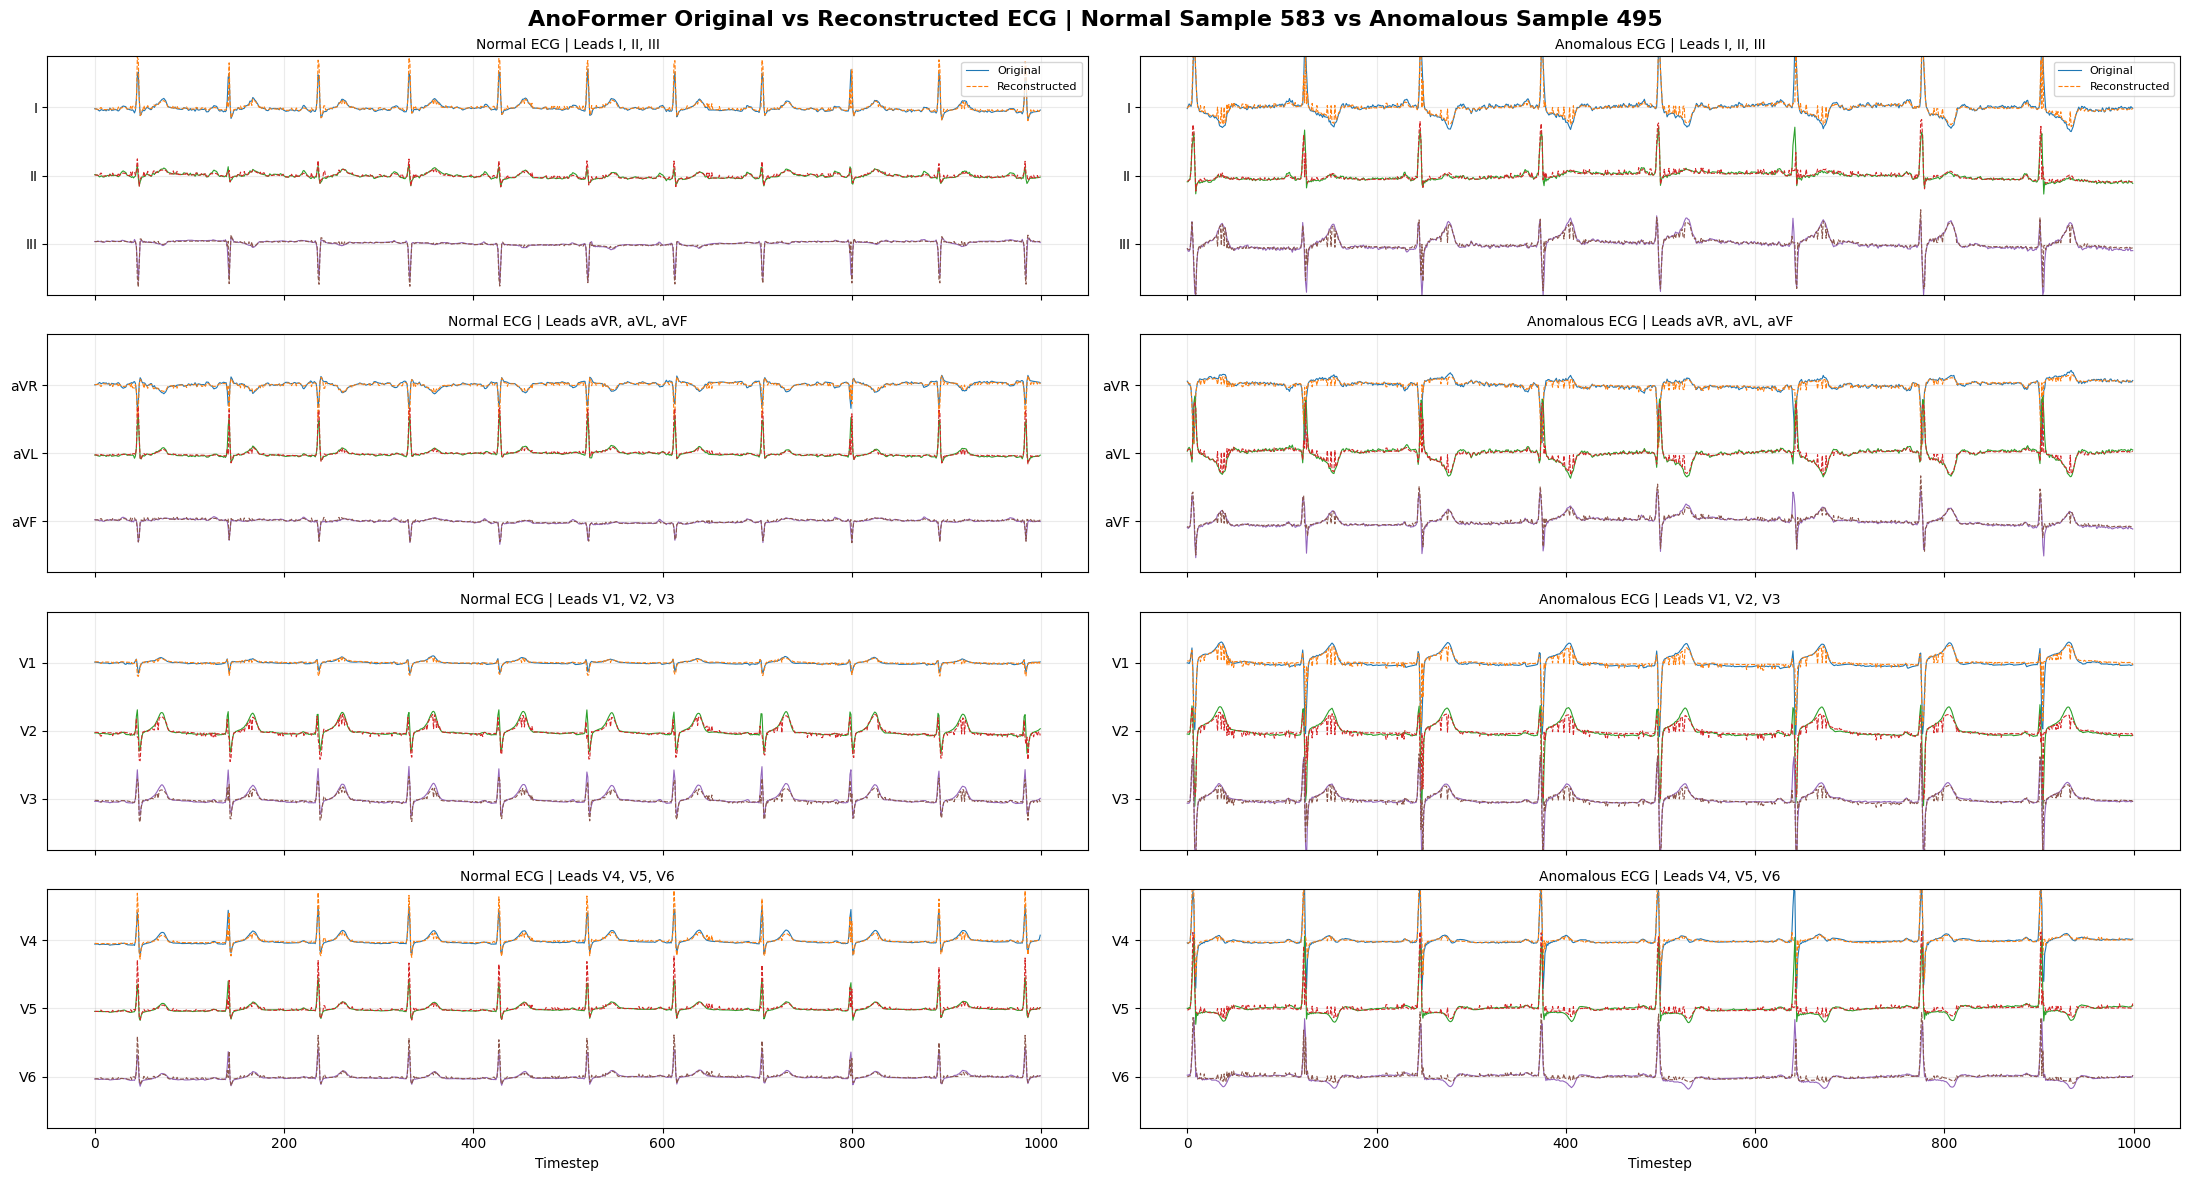

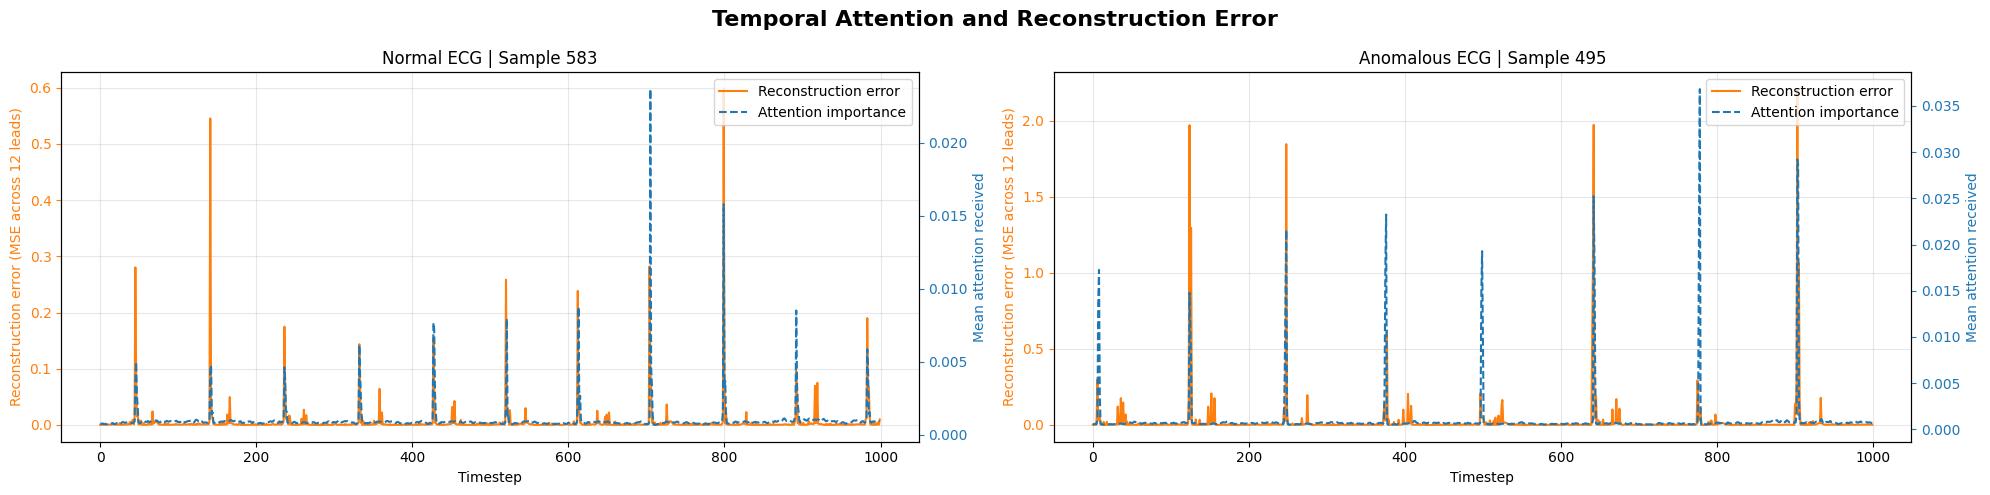

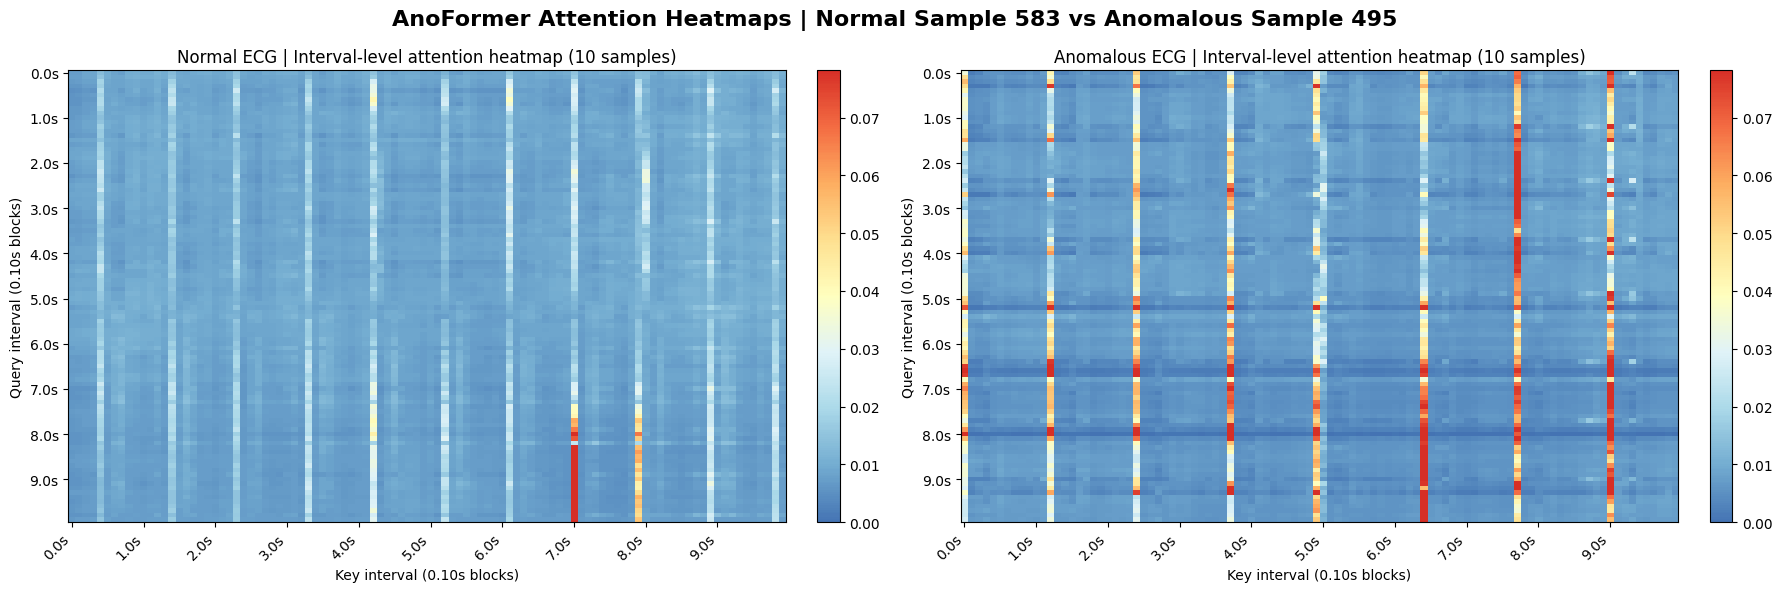

In [24]:
# AnoFormer Attention-based Explainability


print("\n── AnoFormer Attention-based Explainability ─────────────────────")

Explainer = AnoFormerExplainability(AnoFormer)


Explainer.compare_normal_and_anomalous_attention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    BlockIndex=0,
    HeadIndex=None,
    Percentile=99.0,
    UseIntervalHeatmap=True,
    BlockSize=10,
    SamplingRate=100,
)

In [25]:
NormalTemporalAttention = (
    Explainer.get_interval_attention_importance(
        TimeSeriesWindow=NormalECG,
        BlockIndex=0,
        HeadIndex=None,
        BlockSize=10,
    )
)

AnomalousTemporalAttention = (
    Explainer.get_interval_attention_importance(
        TimeSeriesWindow=AnomalousECG,
        BlockIndex=0,
        HeadIndex=None,
        BlockSize=10,
    )
)

print("Normal:", NormalTemporalAttention.shape)
print("Anomalous:", AnomalousTemporalAttention.shape)

Normal: (100,)
Anomalous: (100,)


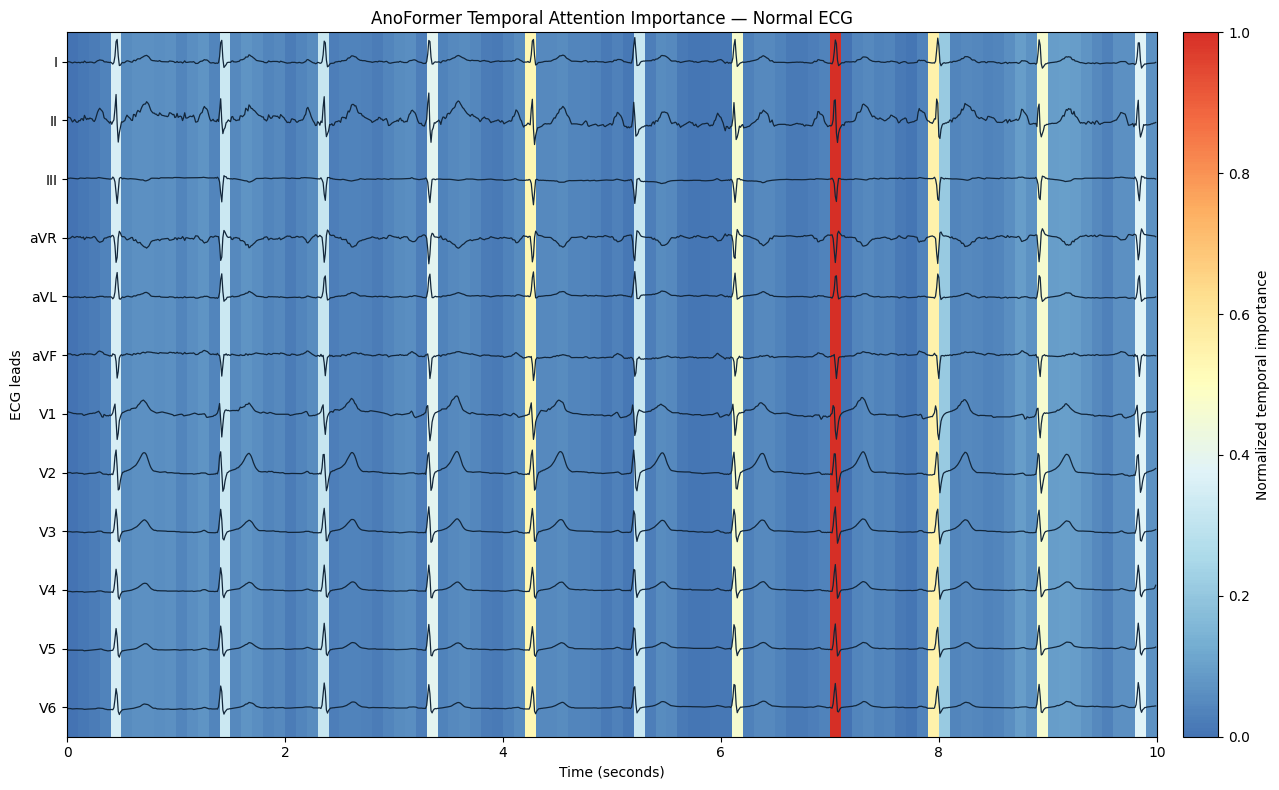

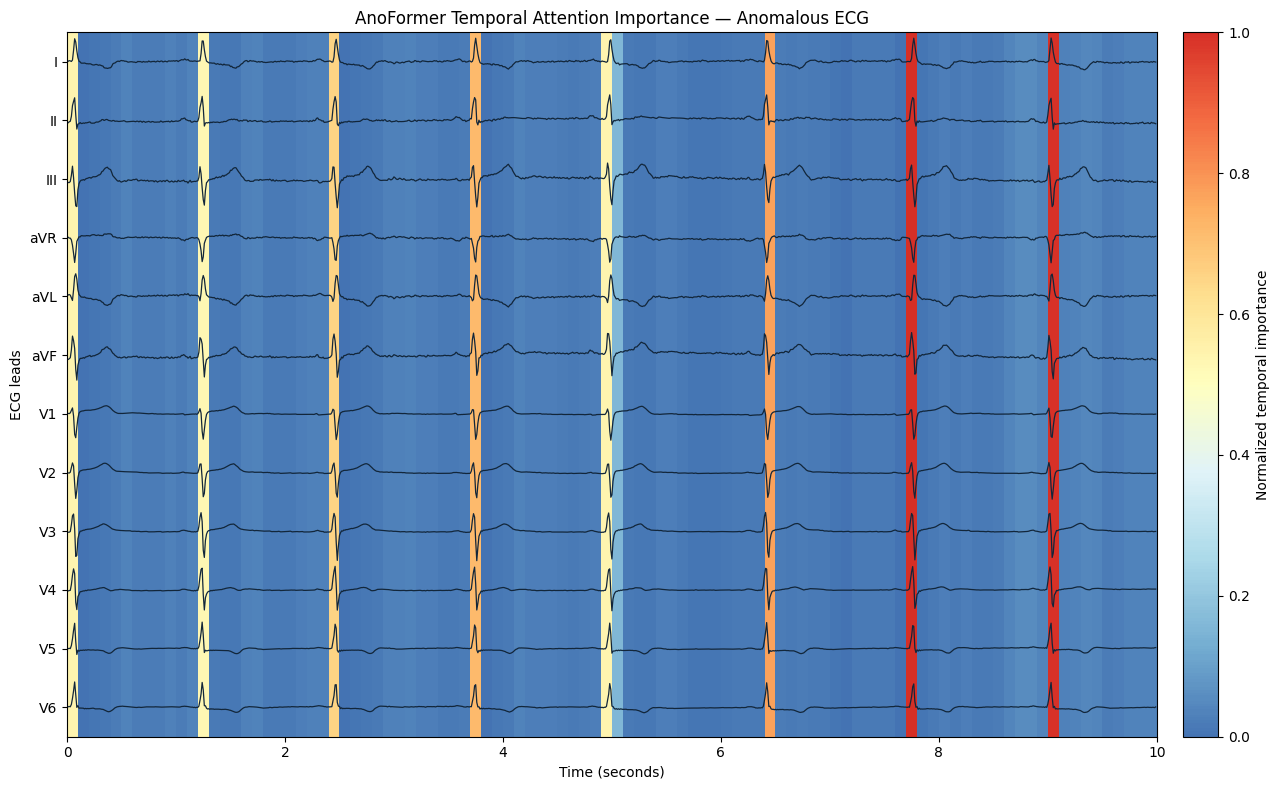

In [26]:
# Now we plot the temporal importance along with ECG leads for comparabel analysis with SHAP later

plot_temporal_importance(
    values=NormalTemporalAttention,
    title="AnoFormer Temporal Attention Importance — Normal ECG",
    ecg=NormalECG.cpu().numpy(),
    save_path=(
        RESULTS_DIR
        / "evaluation"
        / "anoformer_temporal_attention_normal.png"
    ),
)

plot_temporal_importance(
    values=AnomalousTemporalAttention,
    title="AnoFormer Temporal Attention Importance — Anomalous ECG",
    ecg=AnomalousECG.cpu().numpy(),
    save_path=(
        RESULTS_DIR
        / "evaluation"
        / "anoformer_temporal_attention_anomalous.png"
    ),
)

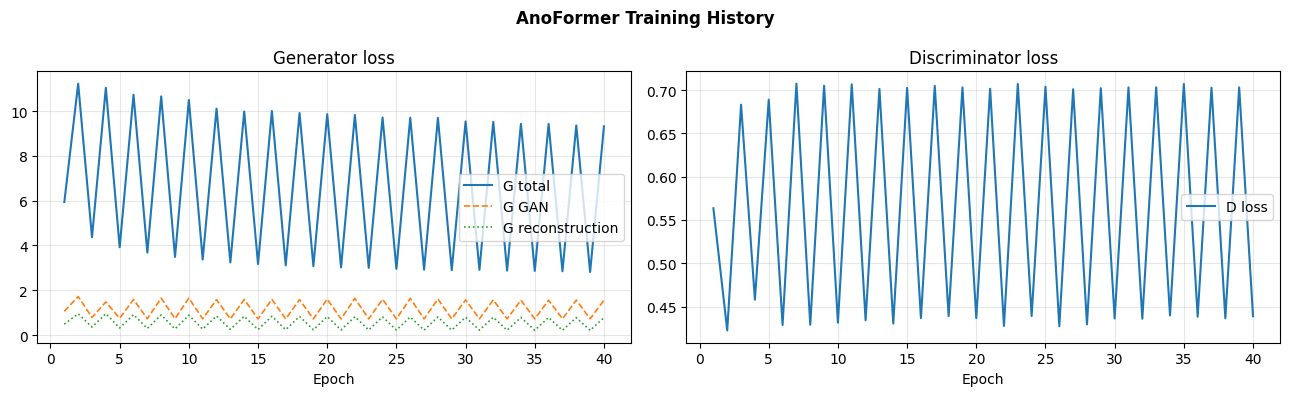

In [27]:
# Show training loss

Explainer.show_training_history()